原始记录数：235674
保留记录数：234864
剔除记录数：810
有效小时数：212083
原始时间范围：1998-01-01 00:00:00 至 2022-10-10 23:00:00（UTC）

前 6 个月（temperature 单位：°C；coverage 为比例）：
            temperature  valid_hours  coverage
DATE                                          
1998-01-01       15.233          586     0.788
1998-02-01       16.875          575     0.856
1998-03-01       19.971          626     0.841
1998-04-01       25.228          624     0.867
1998-05-01       27.098          647     0.870
1998-06-01       28.313          618     0.858

最后 4 个月：
            temperature  valid_hours  coverage
DATE                                          
2022-07-01       30.032          743     0.999
2022-08-01       28.967          733     0.985
2022-09-01       29.954          718     0.997
2022-10-01       28.105          239     0.321

1998—2021 年线性趋势：0.0255 °C/年，即 0.255 °C/十年


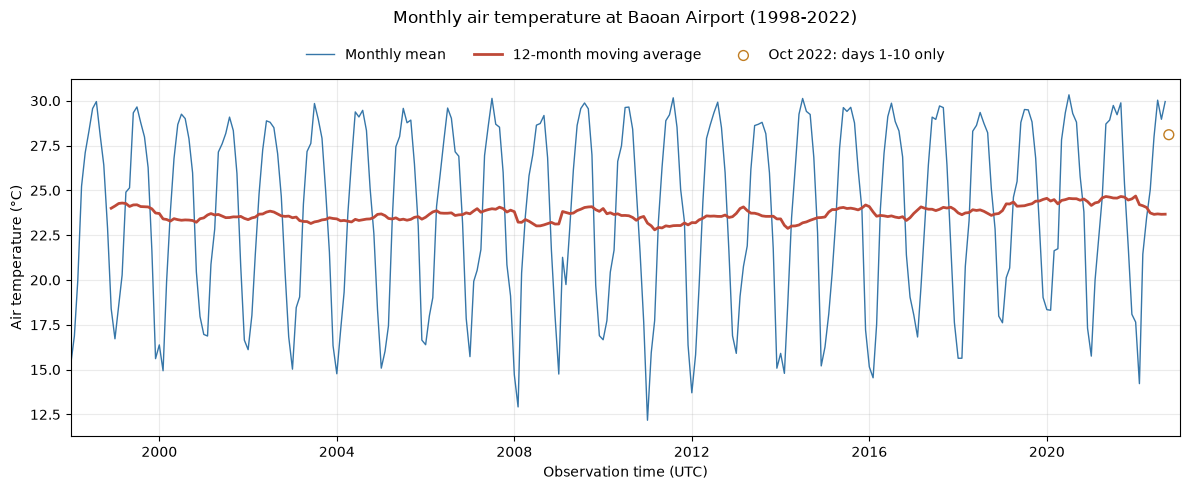

In [1]:
# 作业2：Air temperature in Shenzhen 1998-2022

# 声明引入需要用到的库
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 第一步：读取数据，这里只需要观测时间DATE和气温TMP两列，并且把日期数据转成更好处理的datetime
df = pd.read_csv("Baoan_Weather_1998_2022.csv", usecols=["DATE","TMP"], dtype=str)
df["DATE"] = pd.to_datetime(df["DATE"], errors="coerce")

# 第二步：拆分TMP数据，根据用户指南，例如"+0186,1"的数据表示气温为18.6°C，质量代码为 1，因此分成初始温度和质量
tmp = df["TMP"].str.split(",", expand=True)
df["temp_raw"] = pd.to_numeric(tmp[0], errors="coerce")
df["quality"] = tmp[1].str.strip()

# 根据用户指南："+9999"的数据代表缺测，而不是气温为999.9°C，需要剔除，此外质量标识的0和4代表通过粗限检查，1和5代表通过全部质量检查
# 因此根据between同时排除无法转换的数值和超出用户指南中说明有效范围的数值
valid = (
    df["DATE"].between("1998-01-01", "2022-12-31 23:59:59")
    & df["temp_raw"].ne(9999)
    & df["temp_raw"].between(-932, 618)
    & df["quality"].isin(["0", "1", "4", "5"])
)
# 将筛选过的有效数据放进clean表中，同时通过除以10将TMP数据转化为温度
clean = df.loc[valid, ["DATE", "temp_raw"]].copy()
clean["temperature"] = clean["temp_raw"] / 10

# 重要发现：原始数据中存在同一小时多条记录的情况，如果2014-01-01这天理应只有24个小时的不同数据，但是却有32条记录，因此需要先处理重复时间的记录
# 第三步：先按小时平均，再按月平均，避免记录较多的小时获得更大权重。h表示小时，MS表示以每月第一天即标记该月
hourly = clean.set_index("DATE")["temperature"].resample("h").mean()
monthly = hourly.resample("MS").agg(["mean", "count"])
monthly.columns = ["temperature", "valid_hours"]
# 计算平均温度数据的覆盖率 = 该月有效小时数/该月应有小时数
monthly["coverage"] = monthly["valid_hours"] / (monthly.index.days_in_month * 24)
# 因为原始数据只到2022-10-10，10月不是完整数据且11和12月没有数据，所以趋势分析使用截至 2022 年 9 月的月平均值，仍允许月份内有缺测小时
monthly_complete = monthly.loc[:"2022-09-01", "temperature"]
# 计算12个月移动平均用于减弱季节起伏，方便观察长期变化
smooth = monthly_complete.rolling(window=12, min_periods=12).mean()

# 第四步：用每年12个月的均值估算长期趋势，常规数据每个月权重相同，而2022年没有12个月数据，因此需要注意分析
annual = monthly_complete.groupby(monthly_complete.index.year).agg(["mean", "count"])
annual = annual.loc[annual["count"] == 12]
# polyfit(..., 1)拟合直线：气温 = slope*年份+intercept，slope的单位是°C/年，乘以10就是°C/十年，把尺度拉长看气候变暖趋势
slope, intercept = np.polyfit(annual.index, annual["mean"], 1)

print(f"原始记录数：{len(df)}")
print(f"保留记录数：{len(clean)}")
print(f"剔除记录数：{len(df) - len(clean)}")
print(f"有效小时数：{hourly.count()}")
print(f"原始时间范围：{df['DATE'].min()} 至 {df['DATE'].max()}（UTC）")
print("\n前 6 个月（temperature 单位：°C；coverage 为比例）：")
print(monthly.head(6).round(3).to_string())
print("\n最后 4 个月：")
print(monthly.tail(4).round(3).to_string())
print(f"\n1998—2021 年线性趋势：{slope:.4f} °C/年，"
      f"即 {slope * 10:.3f} °C/十年")

# 第五步：绘制要求的月平均气温与观测时间的关系图
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(monthly_complete.index, monthly_complete,
        color="#3676a8", linewidth=1, label="Monthly mean")
ax.plot(smooth.index, smooth,
        color="#be4938", linewidth=2, label="12-month moving average")
# 用单独的空心点标明不完整的 2022 年 10 月，不与完整月份连线
ax.scatter(pd.Timestamp("2022-10-01"),
           monthly.loc["2022-10-01", "temperature"],
           facecolors="none", edgecolors="#c17d22", s=50,
           label="Oct 2022: days 1-10 only", zorder=3)
ax.set_title("Monthly air temperature at Baoan Airport (1998-2022)", pad=40)
ax.set_xlabel("Observation time (UTC)")
ax.set_ylabel("Air temperature (°C)")
ax.set_xlim(pd.Timestamp("1998-01-01"), pd.Timestamp("2023-01-01"))
ax.grid(alpha=0.25)
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.01),
          ncol=3, frameon=False)
fig.tight_layout()
fig.savefig("baoan_monthly_temperature.png", dpi=200)
plt.show()

# 数据筛选方式说明：
# 分析使用的是宝安国际机场的气温观测数据，依照题意选取DATE和TMP两列进行分析。
# 根据ISD用户指南的说明，TMP由温度编码和质量代码组成，中间由逗号进行分隔，温度编码需除以10才能转换为摄氏度，+9999表示缺测。
# 在分析中保留质量代码为0、1、4、5的记录（质量标识的0和4代表通过粗限检查，1和5代表通过全部质量检查），并剔除缺测、无法解析以及超出指南规定范围的温度。
# 筛选后，共保留234864条观测记录
# 计算时发现原始数据中存在同一小时多条记录的情况，如果2014-01-01这天理应只有24个小时的不同数据，但是却有32条记录，因此需要先处理重复时间的记录。
# 沿用原始UTC时间，先对同一小时内的有效记录求平均，再对各月的有效小时气温求平均，缺测值不使用零值填补。
# 源数据实际截至2022年10月10日，因此该年10月仅作为不完整月份单独标示，不参与移动平均和趋势分析。

# 1998至2022年的月平均气温是否存在变化趋势：
# 月平均气温曲线呈现明显的季节周期，夏季较高，冬季较低。
# 结合12个月移动平均可以看出，气温存在年际波动，长期总体呈缓慢上升趋势。
# 因为整体升温并不意味着每年都比上一年更暖，所以进一步将每年 12 个月的平均气温等权重地进行平均，并对1998—2021年的结果进行线性拟合。
# 得到升温速度约为0.0255°C/年，即 0.255°C/十年。
# 当然以上结论仅仅是大概的描述性趋势，还是会受到缺测和观测覆盖率差异的影响。